In [1]:
import os
import numpy as np
import pandas as pd

In [2]:
url = "https://raw.githubusercontent.com/rayakheraldine/Developer-Burnout-Detector/main/data/developer_burnout_dataset.csv"
df = pd.read_csv(url)
df.head()

,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level,burnout_level,Weekends
0,26.0,12.0,10.33,4.45,2.0,11.0,4.0,1.0,15.07,0.14,55.96,Medium,No
1,39.0,10.0,8.62,5.77,5.0,15.0,11.0,5.0,13.25,0.54,82.22,High,No
2,34.0,13.0,NaN,4.03,5.0,2.0,18.0,9.0,11.18,1.54,61.77,Medium,Yes
3,30.0,1.0,6.85,6.47,2.0,15.0,26.0,1.0,11.14,0.96,54.98,Medium,Yes
4,27.0,7.0,4.24,5.80,NaN,9.0,17.0,7.0,8.05,0.36,27.90,Low,No


In [3]:
df.shape

(7000, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               6860 non-null   float64
 1   experience_years  6860 non-null   float64
 2   daily_work_hours  6860 non-null   float64
 3   sleep_hours       6860 non-null   float64
 4   caffeine_intake   6860 non-null   float64
 5   bugs_per_day      6860 non-null   float64
 6   commits_per_day   6860 non-null   float64
 7   meetings_per_day  6860 non-null   float64
 8   screen_time       6860 non-null   float64
 9   exercise_hours    6860 non-null   float64
 10  stress_level      6860 non-null   float64
 11  burnout_level     6860 non-null   object 
 12  Weekends          7000 non-null   object 
dtypes: float64(11), object(2)
memory usage: 711.1+ KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,6860.0,32.129446,7.230254,20.00,26.0000,32.000,38.0000,44.00
experience_years,6860.0,9.581050,5.760972,0.00,5.0000,10.000,15.0000,19.00
daily_work_hours,6860.0,9.000277,2.863944,4.00,6.5600,8.990,11.4225,14.00
sleep_hours,6860.0,6.485638,1.445008,4.00,5.2200,6.460,7.7400,9.00
caffeine_intake,6860.0,3.540671,2.283445,0.00,2.0000,4.000,6.0000,7.00
bugs_per_day,6860.0,9.482653,5.751664,0.00,5.0000,9.000,14.0000,19.00
commits_per_day,6860.0,14.458455,8.669846,0.00,7.0000,14.000,22.0000,29.00
meetings_per_day,6860.0,4.545044,2.856766,0.00,2.0000,5.000,7.0000,9.00
screen_time,6860.0,11.974773,3.091204,5.21,9.4600,12.020,14.4225,18.93
exercise_hours,6860.0,1.007611,0.576708,0.00,0.5100,1.020,1.5100,2.00


In [6]:
df.isnull().sum()

,0
age,140
experience_years,140
daily_work_hours,140
sleep_hours,140
caffeine_intake,140
bugs_per_day,140
commits_per_day,140
meetings_per_day,140
screen_time,140
exercise_hours,140


In [7]:
# Drop rows with no target label - imputing the label would add made-up answers
df = df.dropna(subset=["burnout_level"])

df = df.dropna(subset=["stress_level"])

# Fill remaining numeric gaps with the median 
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Meetings are counts, so keep them as whole numbers
df["meetings_per_day"] = df["meetings_per_day"].round().astype(int)

# Hours: 2 decimals, same as the original data
df[["sleep_hours", "daily_work_hours"]] = df[["sleep_hours", "daily_work_hours"]].round(2)

# Rescale stress from 0-100 to the 1-10 scale the task asks for
df["stress_level"] = (df["stress_level"] / 10).clip(1, 10).round(1)

print(len(df), "rows left")
df.isnull().sum()

6722 rows left


,0
age,0
experience_years,0
daily_work_hours,0
sleep_hours,0
caffeine_intake,0
bugs_per_day,0
commits_per_day,0
meetings_per_day,0
screen_time,0
exercise_hours,0


In [8]:
# Map the 3 original levels to the 4 target classes the task asks for.
# High is split by stress: 8.5+ (on the 1-10 scale) counts as critical.
df["status"] = df["burnout_level"].map({
    "Low": "Healthy",
    "Medium": "Risk of burnout",
    "High": "Vacation required",
})
df.loc[(df["burnout_level"] == "High") & (df["stress_level"] >= 8.5), "status"] = "Critical condition"

# Keep only the required features (+ the label) under short names for the TS backend
clean = df[["sleep_hours", "meetings_per_day", "Weekends", "stress_level", "status"]].rename(columns={
    "sleep_hours": "sleep",
    "meetings_per_day": "meetings",
    "Weekends": "weekends",
    "stress_level": "stress",
})

os.makedirs("data", exist_ok=True)
clean.to_csv("data/burnout_clean.csv", index=False)
print(clean["status"].value_counts())
clean.head()

status
Risk of burnout       3405
Healthy               1559
Vacation required     1060
Critical condition     698
Name: count, dtype: int64


,sleep,meetings,weekends,stress,status
0,4.45,1,No,5.6,Risk of burnout
1,5.77,5,No,8.2,Vacation required
2,4.03,9,Yes,6.2,Risk of burnout
3,6.47,1,Yes,5.5,Risk of burnout
4,5.80,7,No,2.8,Healthy


## EDA

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

order = ["Healthy", "Risk of burnout", "Vacation required", "Critical condition"]
colors = ["green", "gold", "orange", "red"]

### Class distribution

In [10]:
clean["status"].value_counts()

,count
status,
Risk of burnout,3405
Healthy,1559
Vacation required,1060
Critical condition,698


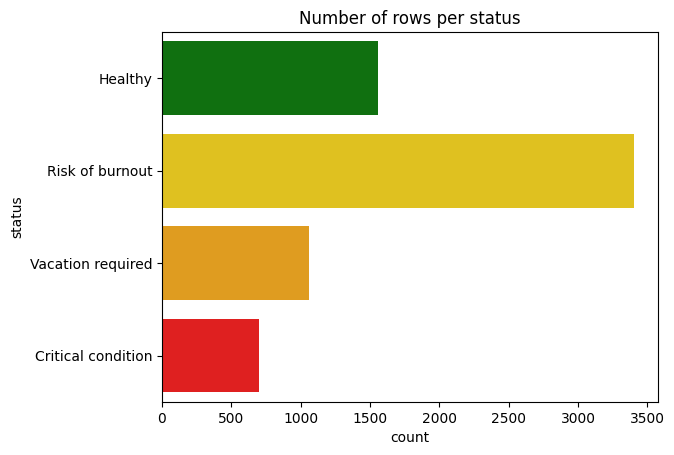

In [11]:
sns.countplot(data=clean, y="status", order=order, hue="status", hue_order=order, palette=colors)
plt.title("Number of rows per status")
plt.show()

### Features by status

In [12]:
clean.groupby("status")[["sleep", "meetings", "stress"]].mean().loc[order]

,sleep,meetings,stress
status,,,
Healthy,6.970289,3.186017,2.294612
Risk of burnout,6.454411,4.597651,5.279765
Vacation required,6.256613,5.351887,7.659623
Critical condition,5.829656,6.308023,9.307736


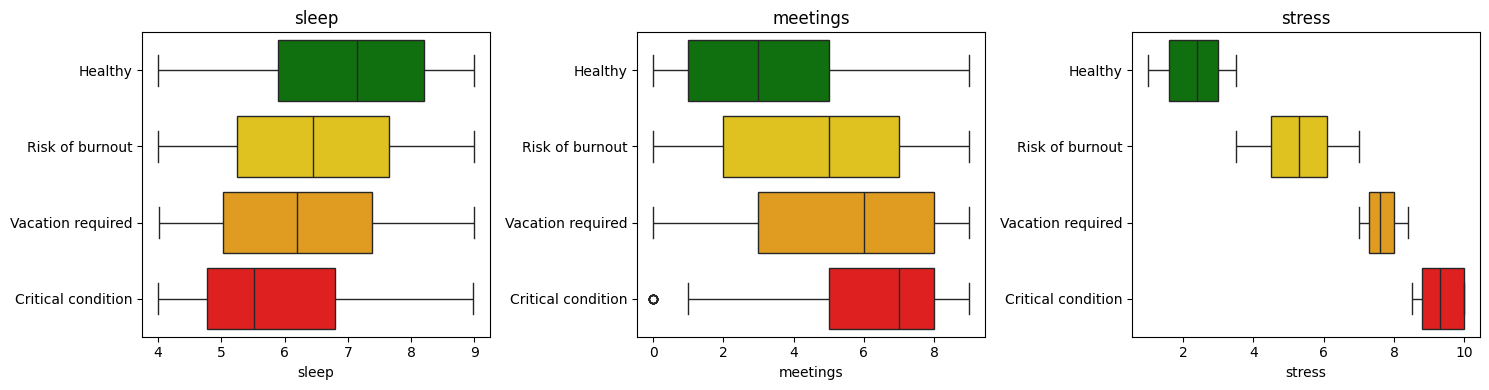

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes.flat, ["sleep", "meetings", "stress"]):
    sns.boxplot(data=clean, x=col, y="status", order=order, hue="status", hue_order=order, palette=colors, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Weekends

In [14]:
weekends_pct = pd.crosstab(clean["weekends"], clean["status"], normalize="index")[order]
weekends_pct.round(2)

status,Healthy,Risk of burnout,Vacation required,Critical condition
weekends,,,,
No,0.34,0.52,0.09,0.04
Yes,0.09,0.48,0.24,0.19


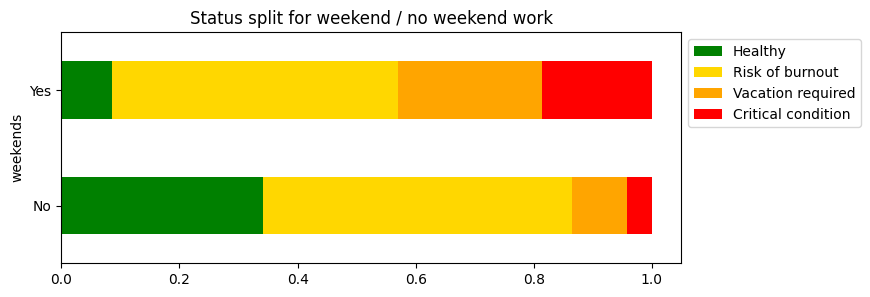

In [15]:
weekends_pct.plot(kind="barh", stacked=True, color=colors, figsize=(8, 3))
plt.title("Status split for weekend / no weekend work")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

### Correlation

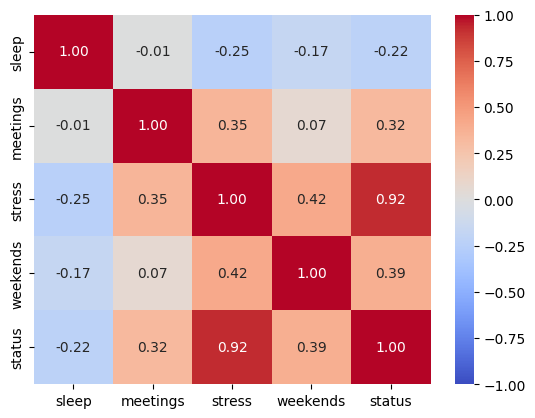

In [16]:
corr_df = clean[["sleep", "meetings", "stress"]].copy()
corr_df["weekends"] = clean["weekends"].map({"No": 0, "Yes": 1})
corr_df["status"] = clean["status"].map({s: i for i, s in enumerate(order)})  # 0 = Healthy ... 3 = Critical

sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

### Stress per status

In [17]:
clean.groupby("status")["stress"].describe().loc[order]

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Healthy,1559.0,2.294612,0.820452,1.0,1.6,2.4,3.0,3.5
Risk of burnout,3405.0,5.279765,0.971004,3.5,4.5,5.3,6.1,7.0
Vacation required,1060.0,7.659623,0.416959,7.0,7.3,7.6,8.0,8.4
Critical condition,698.0,9.307736,0.543434,8.5,8.8,9.3,10.0,10.0


In [18]:
# rows with missing stress got the mean (5.4), so some of them don't match their label
clean[(clean["stress"] == 5.4) & (clean["status"] != "Risk of burnout")]["status"].value_counts()

,count
status,


### Notes
- about half the rows are "Risk of burnout", critical is only ~10% -> classes are unbalanced
- stress is by far the strongest feature (0.92) because the labels were made from it, so the tree will probably split on stress first
- weekends is next, meetings and sleep are weaker
- people who work weekends end up a lot more in the worse categories
- Rows with missing stress were dropped (not imputed), since stress is part of the label definition and a filled value could contradict the label.
- Critical condition is defined using stress ≥ 8.5, so the tree is expected to split on stress near the top.
